# Assignment 1 – Task 2: "Tell the time" from analog clock images

**How to use this notebook**
1. `QUICK_RUN = True`: short sample run (small subsets, 2 epochs) that only checks the pipeline end to end.
2. `QUICK_RUN = False`: full experiments. 

* **Phase A (75×75, prototyping):** classification (24 → 720 classes, plus soft labels), single-output regression (MSE / L1 / SmoothL1), multi-head models (hour head + minute head, α sweep), and trigonometric (sin, cos) encoding with three output designs.
* **Phase B (150×150, final):** the best configuration of each of the four families, retrained with 3 seeds. Final test results are reported only for these.

## 0. Setup & config

In [ ]:
QUICK_RUN = False         # True = short sample run; False = full experiments
USE_DRIVE = True          # on Colab: data + results on Google Drive
RUN_BUDGET = None         # e.g. 20 -> stop after 20 *new* runs (re-run to continue)
RUN_AUG_ABLATION = True   # Phase A extra: best config without augmentation

if QUICK_RUN:
    MAX_EPOCHS, PATIENCE = 2, 2
    MIN_EPOCHS = 1                       
    ...
else:
    MAX_EPOCHS, PATIENCE = 40, 8
    MIN_EPOCHS = 40                      
    SUBSETS = {"train": None, "val": None, "test": None}
PHASE_B_EPOCHS = 2 if QUICK_RUN else 60 

In [ ]:
import glob
import json
import math
import os
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

try:
    from IPython.display import display
except ImportError:
    display = print

IN_COLAB = "google.colab" in sys.modules
if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/IDL_A1"
else:
    ROOT = "."

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    torch.backends.cudnn.benchmark = True
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
USE_AMP = DEVICE.type == "cuda"          # mixed precision (fp16) on the GPU: ~2x faster
print("Device:", DEVICE, "| torch", torch.__version__, "| AMP:", USE_AMP, "| root:", os.path.abspath(ROOT))

CLOCK_DIR = f"{ROOT}/clocks"
OUT_DIR = f"{ROOT}/results_task2" + ("_quick" if QUICK_RUN else "")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(f"{OUT_DIR}/models", exist_ok=True)

SPLIT_SEED = 42
if QUICK_RUN:
    MAX_EPOCHS, PATIENCE = 2, 2
    SEEDS_A, SEEDS_B = [42], [42]
    SUBSETS = {"train": 2000, "val": 500, "test": 500}
else:
    MAX_EPOCHS, PATIENCE = 40, 8
    SEEDS_A = [42, 43]          # prototyping on 75x75
    SEEDS_B = [42, 43, 44]      # final runs on 150x150
    SUBSETS = {"train": None, "val": None, "test": None}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | torch 2.11.0+cu130 | AMP: True | root: /content/drive/MyDrive/IDL_A1


## 1. Data

* Images are stored as `uint8` on the GPU (150×150: about 400 MB) and converted to float per batch.
* Hours are mapped to 0–11 (`12` → `0`), so a time is `t = 60·hour + minute ∈ [0, 720)` minutes.
* One fixed shuffled 80/10/10 split (seed 42), used for every experiment and both resolutions. The two files are assumed to have the same image order; the labels are compared to check this.
* Normalisation uses the mean/std of the training images only.

In [ ]:
def find_files(res):
    """Locate the images file whose images are res x res, and the labels file next to it."""
    cands = sorted(glob.glob(f"{CLOCK_DIR}/**/*.npy", recursive=True))
    img_path = None
    for f in cands:
        if "label" in os.path.basename(f).lower():
            continue
        a = np.load(f, mmap_mode="r")
        if a.ndim >= 3 and list(a.shape[1:]).count(res) >= 2:     # (N,H,W), (N,H,W,1) or (N,1,H,W)
            img_path = f
            break
    if img_path is None:
        return None, None
    same_dir = [f for f in cands if "label" in os.path.basename(f).lower() and os.path.dirname(f) == os.path.dirname(img_path)]
    any_dir = [f for f in cands if "label" in os.path.basename(f).lower()]
    lab_path = (same_dir or any_dir or [None])[0]
    return img_path, lab_path


def load_uint8(path, chunk=2000):
    """Load images as uint8 (N, H, W), converting floats in [0,1] or [0,255] chunk by chunk."""
    arr = np.load(path, mmap_mode="r")
    if arr.ndim == 4:                      # (N, H, W, 1) or (N, 1, H, W)
        arr = arr.reshape(arr.shape[0], arr.shape[-2] if arr.shape[1] == 1 else arr.shape[1], -1)
    if arr.dtype == np.uint8:
        return np.ascontiguousarray(arr)
    scale = 255.0 if float(np.max(arr[:200])) <= 1.0 + 1e-6 else 1.0
    out = np.empty(arr.shape, dtype=np.uint8)
    for i in range(0, len(arr), chunk):
        out[i:i + chunk] = np.clip(np.rint(np.asarray(arr[i:i + chunk], dtype=np.float32) * scale), 0, 255)
    return out


def load_clocks(res):
    img_path, lab_path = find_files(res)
    if img_path is None:
        print(f"No {res}x{res} images found under {CLOCK_DIR}")
        return None
    t0 = time.time()
    imgs = load_uint8(img_path)
    labels = np.load(lab_path).astype(np.int64)
    assert len(imgs) == len(labels), (imgs.shape, labels.shape)
    hours, minutes = labels[:, 0] % 12, labels[:, 1]
    assert minutes.min() >= 0 and minutes.max() <= 59, "minutes outside 0..59"

    n = len(imgs)
    perm = np.random.default_rng(SPLIT_SEED).permutation(n)
    n_tr, n_val = int(0.8 * n), int(0.1 * n)
    idx = {"train": perm[:n_tr], "val": perm[n_tr:n_tr + n_val], "test": perm[n_tr + n_val:]}

    tr_imgs = imgs[idx["train"]]
    mean = float(tr_imgs[::4].mean() / 255.0)
    std = float(tr_imgs[::4].std() / 255.0)

    data = {"res": res, "mean": mean, "std": std, "labels_raw": labels, "img_path": img_path}
    for split, ii in idx.items():
        lim = SUBSETS[split]
        ii = ii[:lim] if lim else ii
        data[split] = (torch.from_numpy(imgs[ii]).unsqueeze(1).to(DEVICE),
                       torch.from_numpy(hours[ii]).to(DEVICE),
                       torch.from_numpy(minutes[ii]).to(DEVICE))
    print(f"{res}x{res}: {img_path} ({imgs.dtype}, {time.time() - t0:.0f}s) | labels {lab_path}")
    print(f"  raw hour range {labels[:, 0].min()}..{labels[:, 0].max()}, minute range {minutes.min()}..{minutes.max()}")
    print(f"  train/val/test = {[len(data[s][0]) for s in ('train', 'val', 'test')]} | pixel mean {mean:.3f} std {std:.3f}")
    return data

75x75: /content/drive/MyDrive/IDL_A1/clocks/75/images.npy (uint8, 0s) | labels /content/drive/MyDrive/IDL_A1/clocks/75/labels.npy
  raw hour range 0..11, minute range 0..59
  train/val/test = [14400, 1800, 1800] | pixel mean 0.598 std 0.218


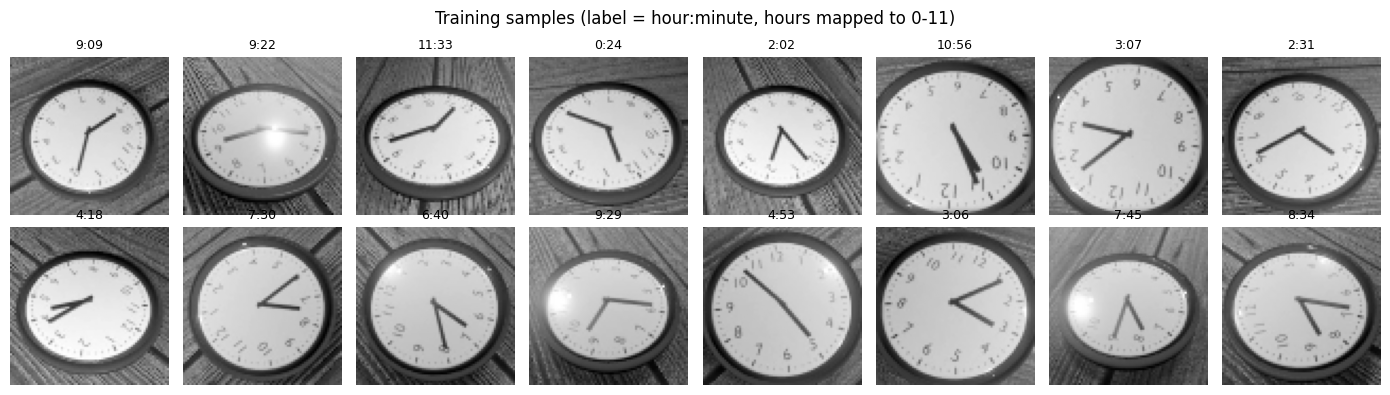

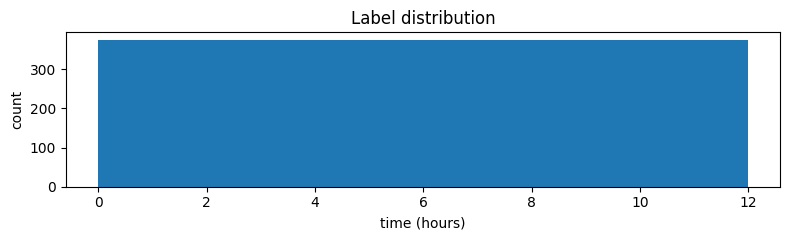

In [ ]:
data75 = load_clocks(75)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
x, h, m = data75["train"]
for i, ax in enumerate(axes.flat):
    ax.imshow(x[i, 0].cpu(), cmap="gray")
    ax.set_title(f"{h[i].item()}:{m[i].item():02d}", fontsize=9)
    ax.axis("off")
plt.suptitle("Training samples (label = hour:minute, hours mapped to 0-11)")
plt.tight_layout()
plt.show()

# Label distribution: is every time equally represented?
t_all = (data75["labels_raw"][:, 0] % 12) * 60 + data75["labels_raw"][:, 1]
plt.figure(figsize=(8, 2.5))
plt.hist(t_all / 60, bins=48)
plt.xlabel("time (hours)"); plt.ylabel("count"); plt.title("Label distribution")
plt.tight_layout(); plt.show()

## 2. Common-sense error (CSE)
`CSE = min(|Δ| mod 720, 720 − |Δ| mod 720)` in minutes, so predicting 11:55 for 0:05 costs 10 minutes. Random guessing gives 180 minutes on average. Predicted times are rounded to whole minutes before scoring, because labels are whole minutes.

In [ ]:
def cse(pred_min, true_min):
    d = torch.remainder(pred_min - true_min, 720.0) if torch.is_tensor(pred_min) else np.mod(pred_min - true_min, 720.0)
    return torch.minimum(d, 720.0 - d) if torch.is_tensor(d) else np.minimum(d, 720.0 - d)


def signed_error(pred_min, true_min):
    """Signed error in (-360, 360]: positive = predicted later than the truth."""
    return np.mod(np.asarray(pred_min) - np.asarray(true_min) + 360.0, 720.0) - 360.0


def cse_metrics(err):
    err = np.asarray(err, dtype=np.float64)
    return {"mean": float(err.mean()), "median": float(np.median(err)), "p90": float(np.percentile(err, 90)),
            "within1": float((err <= 1).mean()), "within5": float((err <= 5).mean()),
            "within30": float((err <= 30).mean())}


assert cse(torch.tensor(715.0), torch.tensor(5.0)).item() == 10.0     # 11:55 vs 0:05
assert cse(torch.tensor(180.0), torch.tensor(540.0)).item() == 360.0  # 3:00 vs 9:00
print("CSE checks passed")

CSE checks passed


## 3. Label encodings
Each encoding defines the output heads (name → size), the training targets, the loss, an optional output activation (`post`), and how to **decode** the outputs into a time in minutes. The decoded time is what CSE scores, so every formulation is compared on the same metric.

| Encoding | Heads | Loss | Decoding |
|---|---|---|---|
| `cls` (n classes) | time: n | cross-entropy (optionally soft circular-Gaussian labels) | centre of the arg-max bin |
| `reg` | time: 1 (hours as a float, 3:30 → 3.5) | MSE / L1 / SmoothL1 | `out · 60 mod 720` |
| `mh` | hour: 12 or 1, minute: 60 or 1 | `L_hour + α · L_minute` | hour (arg-max, or rounded from the hour-hand position) · 60 + minute |
| `trig` | hour: 2, minute: 2 = (sin θ, cos θ) per hand | MSE on the unit-circle points | `atan2` → angles → time |

For the hour **regression** head and the trig encoding, the hour target is the continuous hour-hand position `h + m/60`. When decoding, the hour is taken as `round(position − minute/60) mod 12`. This keeps hour and minute consistent near the full hour (at 2:59 the hour hand is almost at 3).

In [ ]:
def minutes_of(h, m):
    return h * 60 + m


def circ_dist(a, b, period):
    d = torch.remainder(a - b, period)
    return torch.minimum(d, period - d)


REG_LOSSES = {"mse": F.mse_loss, "l1": F.l1_loss, "smoothl1": F.smooth_l1_loss}


class ClsEnc:
    def __init__(self, n, soft_sigma=0.0, label_smoothing=0.0):
        assert 720 % n == 0, "n must divide 720"
        self.n, self.w = n, 720 // n
        self.heads = {"time": n}
        self.sigma, self.ls = soft_sigma, label_smoothing

    def centers(self, device):
        return torch.arange(self.n, device=device, dtype=torch.float32) * self.w + (self.w - 1) / 2

    def post(self, out):
        return out

    def loss(self, out, h, m):
        t = minutes_of(h, m)
        logits = out["time"]
        if self.sigma > 0:      # soft labels: probability mass on neighbouring (also wrapped) classes
            d = circ_dist(t[:, None].float(), self.centers(t.device)[None], 720.0)
            target = torch.softmax(-d ** 2 / (2 * self.sigma ** 2), dim=1)
            return -(target * F.log_softmax(logits, dim=1)).sum(1).mean()
        return F.cross_entropy(logits, torch.div(t, self.w, rounding_mode="floor"), label_smoothing=self.ls)

    def decode(self, out):
        return self.centers(out["time"].device)[out["time"].argmax(1)]


class RegEnc:
    def __init__(self, reg_loss="smoothl1"):
        self.heads = {"time": 1}
        self.lf = REG_LOSSES[reg_loss]

    def post(self, out):
        return out

    def loss(self, out, h, m):
        return self.lf(out["time"][:, 0], minutes_of(h, m).float() / 60.0)

    def decode(self, out):
        return torch.remainder(out["time"][:, 0] * 60.0, 720.0)


class MultiHeadEnc:
    def __init__(self, hour="cls", minute="cls", alpha=1.0, reg_loss="smoothl1"):
        self.hour_mode, self.min_mode, self.alpha = hour, minute, alpha
        self.heads = {"hour": 12 if hour == "cls" else 1, "minute": 60 if minute == "cls" else 1}
        self.lf = REG_LOSSES[reg_loss]

    def post(self, out):
        return out

    def loss(self, out, h, m):
        if self.hour_mode == "cls":
            l_h = F.cross_entropy(out["hour"], h)
        else:                                   # hour-hand position in [0, 12)
            l_h = self.lf(out["hour"][:, 0], h.float() + m.float() / 60.0)
        if self.min_mode == "cls":
            l_m = F.cross_entropy(out["minute"], m)
        else:                                   # minute scaled to [0, 12) like the hour
            l_m = self.lf(out["minute"][:, 0], m.float() / 5.0)
        return l_h + self.alpha * l_m

    def decode(self, out):
        if self.min_mode == "cls":
            mp = out["minute"].argmax(1).float()
        else:
            mp = torch.remainder(out["minute"][:, 0] * 5.0, 60.0)
        if self.hour_mode == "cls":
            hp = out["hour"].argmax(1).float()
        else:
            hpos = torch.remainder(out["hour"][:, 0], 12.0)
            hp = torch.remainder(torch.round(hpos - mp / 60.0), 12.0)
        return hp * 60.0 + mp


class TrigEnc:
    """Predict (sin, cos) of the hour-hand and minute-hand angles."""

    def __init__(self, act="unit", alpha=1.0):
        self.heads = {"hour": 2, "minute": 2}
        self.act, self.alpha = act, alpha

    def post(self, out):
        f = {"none": lambda z: z, "tanh": torch.tanh, "unit": lambda z: F.normalize(z, dim=1, eps=1e-6)}[self.act]
        return {k: f(v) for k, v in out.items()}

    @staticmethod
    def angles(h, m):
        hf, mf = h.float(), m.float()
        th = 2 * math.pi * (hf + mf / 60.0) / 12.0
        tm = 2 * math.pi * mf / 60.0
        return th, tm

    def loss(self, out, h, m):
        th, tm = self.angles(h, m)
        yh = torch.stack([torch.sin(th), torch.cos(th)], 1)
        ym = torch.stack([torch.sin(tm), torch.cos(tm)], 1)
        return F.mse_loss(out["hour"], yh) + self.alpha * F.mse_loss(out["minute"], ym)

    @staticmethod
    def _angle(v):
        return torch.remainder(torch.atan2(v[:, 0], v[:, 1]), 2 * math.pi)

    def decode(self, out):
        mp = self._angle(out["minute"]) * 60.0 / (2 * math.pi)
        hpos = self._angle(out["hour"]) * 12.0 / (2 * math.pi)
        hp = torch.remainder(torch.round(hpos - mp / 60.0), 12.0)
        return hp * 60.0 + mp


def make_encoding(cfg):
    e = cfg["encoding"]
    if e == "cls":
        return ClsEnc(cfg["n_classes"], cfg.get("soft_sigma", 0.0), cfg.get("label_smoothing", 0.0))
    if e == "reg":
        return RegEnc(cfg["reg_loss"])
    if e == "mh":
        return MultiHeadEnc(cfg["hour"], cfg["minute"], cfg["alpha"], cfg.get("reg_loss", "smoothl1"))
    if e == "trig":
        return TrigEnc(cfg["act"], cfg.get("alpha", 1.0))
    raise ValueError(e)


# Sanity check: decoding the *perfect* outputs of every encoding gives back the true time
_h = torch.tensor([0, 2, 11, 5, 11]); _m = torch.tensor([0, 59, 59, 30, 1]); _t = minutes_of(_h, _m).float()
_th, _tm = TrigEnc.angles(_h, _m)
perfect = {
    "trig": {"hour": torch.stack([torch.sin(_th), torch.cos(_th)], 1), "minute": torch.stack([torch.sin(_tm), torch.cos(_tm)], 1)},
    "mh-reg": {"hour": (_h + _m / 60.0)[:, None].float(), "minute": (_m / 5.0)[:, None].float()},
    "mh-cls": {"hour": F.one_hot(_h, 12).float(), "minute": F.one_hot(_m, 60).float()},
    "reg": {"time": (_t / 60.0)[:, None]},
    "cls720": {"time": F.one_hot(_t.long(), 720).float()},
}
encs = {"trig": TrigEnc(), "mh-reg": MultiHeadEnc("reg", "reg"), "mh-cls": MultiHeadEnc("cls", "cls"),
        "reg": RegEnc(), "cls720": ClsEnc(720)}
for k, enc in encs.items():
    err = cse(torch.round(enc.decode(perfect[k])), _t).max().item()
    assert err < 1e-4, (k, err)
print("Encoding round-trip checks passed")

Encoding round-trip checks passed


## 4. Model: shared CNN backbone + heads
`[Conv3×3 → BN → ReLU] × 2 → MaxPool` per block (channels 32, 64, 128, 256), then `AdaptiveAvgPool2d(4)`, which keeps a coarse 4×4 spatial layout (where the hands point matters), then `Linear(4096 → 512) → ReLU → Dropout`. One `nn.Linear` head per output. The same module works for 75×75 and 150×150 inputs. With two heads, `forward` returns them as a tuple: `out_hour, out_minute = model(x)`.

In [ ]:
class ClockNet(nn.Module):
    def __init__(self, heads, channels=(32, 64, 128, 256), fc=512, dropout=0.3, stem=False):
        super().__init__()
        layers, c = [], 1
        if stem:   # stride-2 conv: 150x150 -> 75x75, so the rest of the network sees the clock at the Phase A scale
            layers += [nn.Conv2d(1, 16, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True)]
            c = 16
        layers += [nn.AdaptiveAvgPool2d(4), nn.Flatten(), nn.Linear(c * 16, fc), nn.ReLU(inplace=True), nn.Dropout(dropout)]
        self.backbone = nn.Sequential(*layers)
        self.head_names = list(heads)
        self.heads = nn.ModuleDict({k: nn.Linear(fc, d) for k, d in heads.items()})

    def forward(self, x):
        f = self.backbone(x)
        outs = tuple(self.heads[k](f) for k in self.head_names)
        return outs if len(outs) > 1 else outs[0]


def as_dict(model, outs):
    outs = outs if isinstance(outs, tuple) else (outs,)
    return {k: v.float() for k, v in zip(model.head_names, outs)}


_m = ClockNet({"hour": 12, "minute": 60})
out_hour, out_minute = _m(torch.zeros(2, 1, 75, 75))
print("multi-head output shapes:", tuple(out_hour.shape), tuple(out_minute.shape),
      "| params:", sum(p.numel() for p in _m.parameters()))

multi-head output shapes: (2, 12) (2, 60) | params: 45640


## 5. Training, augmentation and the run store
* AdamW (lr 1e-3, weight decay 1e-4), cosine LR schedule, batch 128, gradient clipping at norm 5. Up to `MAX_EPOCHS` epochs with early stopping on **validation mean CSE** (patience `PATIENCE`); the best checkpoint is restored.
* **Augmentation** (training only, on the GPU): random brightness (±0.1) and contrast (×0.8–1.2), plus small translations (up to 4 % of the image). **No rotations or flips**: rotating or mirroring the clock changes the time it shows, so the label would be wrong.
* Each run stores its config, per-epoch history, validation metrics, test metrics and test predictions in `runs.jsonl`. Test numbers are never used for selection.

In [ ]:
BATCH_SIZE = 128


def prep_batch(xb, data, augment):
    x = xb.float() / 255.0
    if augment:
        b = x.shape[0]
        mu = x.mean(dim=(1, 2, 3), keepdim=True)
        contrast = torch.empty(b, 1, 1, 1, device=x.device).uniform_(0.8, 1.2)
        bright = torch.empty(b, 1, 1, 1, device=x.device).uniform_(-0.1, 0.1)
        x = ((x - mu) * contrast + mu + bright).clamp(0, 1)
        shift = torch.empty(b, 2, device=x.device).uniform_(-0.08, 0.08)   # in [-1,1] coords = ±4 % of size
        theta = torch.zeros(b, 2, 3, device=x.device)
        theta[:, 0, 0] = 1; theta[:, 1, 1] = 1; theta[:, :, 2] = shift
        grid = F.affine_grid(theta, x.shape, align_corners=False)
        x = F.grid_sample(x, grid, padding_mode="border", align_corners=False)
    x = (x - data["mean"]) / data["std"]
    return x.contiguous(memory_format=torch.channels_last)


@torch.no_grad()
def predict(model, enc, data, split, bs=512):
    model.eval()
    x, h, m = data[split]
    preds = []
    for i in range(0, len(x), bs):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            outs = model(prep_batch(x[i:i + bs], data, False))
        preds.append(torch.round(enc.decode(enc.post(as_dict(model, outs)))))
    pred = torch.remainder(torch.cat(preds), 720.0)
    true = minutes_of(h, m).float()
    return pred.cpu().numpy(), true.cpu().numpy()


def train_run(cfg, data, seed, max_epochs, patience, save_path=None, verbose=False):
    set_seed(seed)
    enc = make_encoding(cfg)
    model = ClockNet(enc.heads, cfg["channels"], cfg["fc"], cfg["dropout"], stem=cfg.get("stem", False)).to(DEVICE)
    model = model.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    x_tr, h_tr, m_tr = data["train"]

    hist = {"train_loss": [], "val_mean": [], "val_median": []}
    best = (float("inf"), 0, None)
    bad = 0
    t0 = time.time()
    for ep in range(1, max_epochs + 1):
        model.train()
        loss_sum = torch.zeros((), device=DEVICE)
        n_seen = 0
        perm = torch.randperm(len(x_tr), device=x_tr.device)
        for i in range(0, len(x_tr), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            xb = prep_batch(x_tr[idx], data, cfg["augment"])
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                outs = model(xb)
            loss = enc.loss(enc.post(as_dict(model, outs)), h_tr[idx], m_tr[idx])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt)
            scaler.update()
            loss_sum += loss.detach() * len(idx)
            n_seen += len(idx)
        sched.step()
        tr_loss = loss_sum.item() / n_seen
        pv, tv = predict(model, enc, data, "val")
        ev = cse(pv, tv)
        hist["train_loss"].append(tr_loss)
        hist["val_mean"].append(float(ev.mean()))
        hist["val_median"].append(float(np.median(ev)))
        if verbose:
            print(f"  ep {ep:3d} | loss {tr_loss:.4f} | val CSE mean {ev.mean():6.2f} min, median {np.median(ev):5.1f}")
        if not np.isfinite(tr_loss):
            print("  -> loss diverged, stopping")
            break
        if ev.mean() < best[0]:
            best = (float(ev.mean()), ep, {k: v.detach().clone() for k, v in model.state_dict().items()})
            bad = 0
        else:
            bad += 1
            if bad >= patience and ep >= MIN_EPOCHS:
                break

    if best[2] is not None:
        model.load_state_dict(best[2])
    pv, tv = predict(model, enc, data, "val")
    pt, tt = predict(model, enc, data, "test")
    if save_path:
        torch.save(model.state_dict(), save_path)
    summary = {"min_epochs": MIN_EPOCHS, "best_epoch": best[1], "epochs_run": len(hist["val_mean"]), "time_s": time.time() - t0,
               "params": sum(p.numel() for p in model.parameters()),
               "val": cse_metrics(cse(pv, tv)), "test": cse_metrics(cse(pt, tt))}
    del model
    return {"summary": summary, "hist": hist,
            "test_pred": pt.astype(int).tolist(), "test_true": tt.astype(int).tolist()}


# ---------- persistent store ----------
STORE_PATH = f"{OUT_DIR}/runs.jsonl"
STORE = {}
if os.path.exists(STORE_PATH):
    with open(STORE_PATH) as f:
        for line in f:
            if line.strip():
                r = json.loads(line)
                STORE[r["key"]] = r
print(f"Run store: {STORE_PATH} ({len(STORE)} finished runs loaded)")
NEW_RUNS = 0


class BudgetReached(Exception):
    pass


def run_key(cfg, res, seed):
    return json.dumps({"cfg": cfg, "res": res, "seed": seed, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
                       "subsets": SUBSETS}, sort_keys=True)

def is_done(cfg, res, seed):
    """Finished = stored, and not a run that early stopping cut off under the old rule (no MIN_EPOCHS)."""
    r = STORE.get(run_key(cfg, res, seed))
    if r is None:
        return False
    cut_off = r["summary"]["epochs_run"] < cfg.get("epochs", MAX_EPOCHS) and r["summary"].get("min_epochs", 0) < MIN_EPOCHS
    return not cut_off

def get_run(cfg, data, seed, save=False, verbose=False):
    global NEW_RUNS
    key = run_key(cfg, data["res"], seed)
    if is_done(cfg, data["res"], seed):
        return STORE[key]
    if RUN_BUDGET is not None and NEW_RUNS >= RUN_BUDGET:
        raise BudgetReached(f"RUN_BUDGET={RUN_BUDGET} reached; progress is saved, run the notebook again to continue.")
    save_path = (os.path.join(OUT_DIR, "models", f"{cfg['name'].replace('/', '-').replace(' ', '_')}_{data['res']}px_seed{seed}.pt")
                 if save else None)
    rec = train_run(cfg, data, seed, cfg.get("epochs", MAX_EPOCHS), PATIENCE, save_path=save_path, verbose=verbose)
    rec.update({"key": key, "cfg": cfg, "res": data["res"], "seed": seed, "model_path": save_path})
    with open(STORE_PATH, "a") as f:
        f.write(json.dumps(rec) + "\n")
        f.flush()
        os.fsync(f.fileno())
    STORE[key] = rec
    NEW_RUNS += 1
    return rec


def run_configs(cfgs, data, seeds, tag, save=False):
    todo = [(c, s) for c in cfgs for s in seeds if not is_done(c, data["res"], s)]
    print(f"{tag}: {len(cfgs)} configs x {len(seeds)} seeds -> {len(todo)} runs to do")
    t0 = time.time()
    for i, (c, s) in enumerate(todo, 1):
        rec = get_run(c, data, s, save=save and s == seeds[0], verbose=(data["res"] == 150))
        sm = rec["summary"]
        el = time.time() - t0
        print(f"[{tag} {i:3d}/{len(todo)}] {c['name']:22s} seed {s} | val CSE {sm['val']['mean']:7.2f} min "
              f"(median {sm['val']['median']:5.1f}) | best ep {sm['best_epoch']}/{sm['epochs_run']} | "
              f"{el / 60:.1f} min, ETA {el / i * (len(todo) - i) / 60:.1f} min")


def _std(v):
    return float(np.std(v, ddof=1)) if len(v) > 1 else float("nan")


def summarize(cfgs, res, seeds, show_test=False):
    rows = []
    for c in cfgs:
        recs = [STORE[run_key(c, res, s)] for s in seeds]
        v = [r["summary"]["val"]["mean"] for r in recs]
        row = {"name": c["name"], "family": c["family"], "res": res,
               "val_cse": float(np.mean(v)), "val_cse_std": _std(v),
               "val_median": float(np.mean([r["summary"]["val"]["median"] for r in recs])),
               "best_epoch": float(np.mean([r["summary"]["best_epoch"] for r in recs])),
               "time_min": float(np.sum([r["summary"]["time_s"] for r in recs]) / 60)}
        if show_test:
            tm = [r["summary"]["test"] for r in recs]
            row.update({"test_cse": float(np.mean([t["mean"] for t in tm])), "test_cse_std": _std([t["mean"] for t in tm]),
                        "test_median": float(np.mean([t["median"] for t in tm])),
                        "test_p90": float(np.mean([t["p90"] for t in tm])),
                        "within1_%": 100 * float(np.mean([t["within1"] for t in tm])),
                        "within5_%": 100 * float(np.mean([t["within5"] for t in tm]))})
        rows.append(row)
    return pd.DataFrame(rows)

Run store: /content/drive/MyDrive/IDL_A1/results_task2/runs.jsonl (60 finished runs loaded)


## 6. Phase A: all formulations on 75×75

The classification floor is the mean CSE a *perfect* bin classifier would still have, caused by quantisation (for whole-minute labels uniformly spread in a bin of width w: about w/4). It is shown as a reference.

In [ ]:
BASE = dict(channels=[32, 64, 128, 256], fc=512, dropout=0.3, lr=1e-3, weight_decay=1e-4, augment=True)

CONFIGS_A = [
    dict(name="cls-24", family="classification", encoding="cls", n_classes=24),
    dict(name="cls-72", family="classification", encoding="cls", n_classes=72),
    dict(name="cls-144", family="classification", encoding="cls", n_classes=144),
    dict(name="cls-360", family="classification", encoding="cls", n_classes=360),
    dict(name="cls-720", family="classification", encoding="cls", n_classes=720),
    dict(name="cls-720-soft", family="classification", encoding="cls", n_classes=720, soft_sigma=3.0),
    dict(name="reg-mse", family="regression", encoding="reg", reg_loss="mse"),
    dict(name="reg-l1", family="regression", encoding="reg", reg_loss="l1"),
    dict(name="reg-smoothl1", family="regression", encoding="reg", reg_loss="smoothl1"),
    dict(name="mh-cls/cls", family="multi-head", encoding="mh", hour="cls", minute="cls", alpha=1.0),
    dict(name="mh-cls/reg a=0.3", family="multi-head", encoding="mh", hour="cls", minute="reg", alpha=0.3),
    dict(name="mh-cls/reg a=1", family="multi-head", encoding="mh", hour="cls", minute="reg", alpha=1.0),
    dict(name="mh-cls/reg a=3", family="multi-head", encoding="mh", hour="cls", minute="reg", alpha=3.0),
    dict(name="mh-reg/reg", family="multi-head", encoding="mh", hour="reg", minute="reg", alpha=1.0),
    dict(name="trig-linear", family="trig", encoding="trig", act="none"),
    dict(name="trig-tanh", family="trig", encoding="trig", act="tanh"),
    dict(name="trig-unit", family="trig", encoding="trig", act="unit"),
]
CONFIGS_A = [{**BASE, **c} for c in CONFIGS_A]
FAMILIES = ["classification", "regression", "multi-head", "trig"]
FAMILY_COLOR = {"classification": "tab:blue", "regression": "tab:orange", "multi-head": "tab:green", "trig": "tab:purple"}


def cls_floor(cfg):
    if cfg["encoding"] != "cls":
        return float("nan")
    w = 720 // cfg["n_classes"]
    c = (w - 1) / 2
    return float(np.mean(np.abs(np.arange(w) - c)))

In [ ]:
run_configs(CONFIGS_A, data75, SEEDS_A, "phaseA-75px")
dfA = summarize(CONFIGS_A, 75, SEEDS_A)
dfA["cls_floor"] = [cls_floor(c) for c in CONFIGS_A]
dfA.to_csv(f"{OUT_DIR}/phaseA_75px.csv", index=False)
dfA.round(2)

phaseA-75px: 17 configs x 2 seeds -> 4 runs to do
[phaseA-75px   1/4] cls-360                seed 43 | val CSE  132.22 min (median 113.0) | best ep 31/40 | 0.2 min, ETA 0.6 min
[phaseA-75px   2/4] cls-720-soft           seed 42 | val CSE  116.64 min (median 103.0) | best ep 30/40 | 0.5 min, ETA 0.5 min
[phaseA-75px   3/4] cls-720-soft           seed 43 | val CSE  117.16 min (median 105.0) | best ep 20/40 | 0.7 min, ETA 0.2 min
[phaseA-75px   4/4] trig-tanh              seed 42 | val CSE  107.36 min (median  99.5) | best ep 28/40 | 1.0 min, ETA 0.0 min


,name,family,res,val_cse,val_cse_std,val_median,best_epoch,time_min,cls_floor
0,cls-24,classification,75,62.11,76.94,53.00,33.0,2.86,7.5
1,cls-72,classification,75,65.93,28.60,4.50,36.0,5.27,2.5
2,cls-144,classification,75,89.91,50.25,56.50,35.0,2.85,1.2
3,cls-360,classification,75,133.85,2.30,113.50,32.0,0.45,0.5
4,cls-720,classification,75,138.88,0.14,117.50,36.5,0.44,0.0
5,cls-720-soft,classification,75,116.90,0.37,104.00,25.0,0.49,0.0
6,reg-mse,regression,75,14.55,2.30,10.50,39.5,5.23,NaN
7,reg-l1,regression,75,16.16,4.37,10.50,37.5,5.24,NaN
8,reg-smoothl1,regression,75,13.85,2.40,10.00,37.5,5.25,NaN
9,mh-cls/cls,multi-head,75,92.29,27.36,67.00,37.5,2.88,NaN


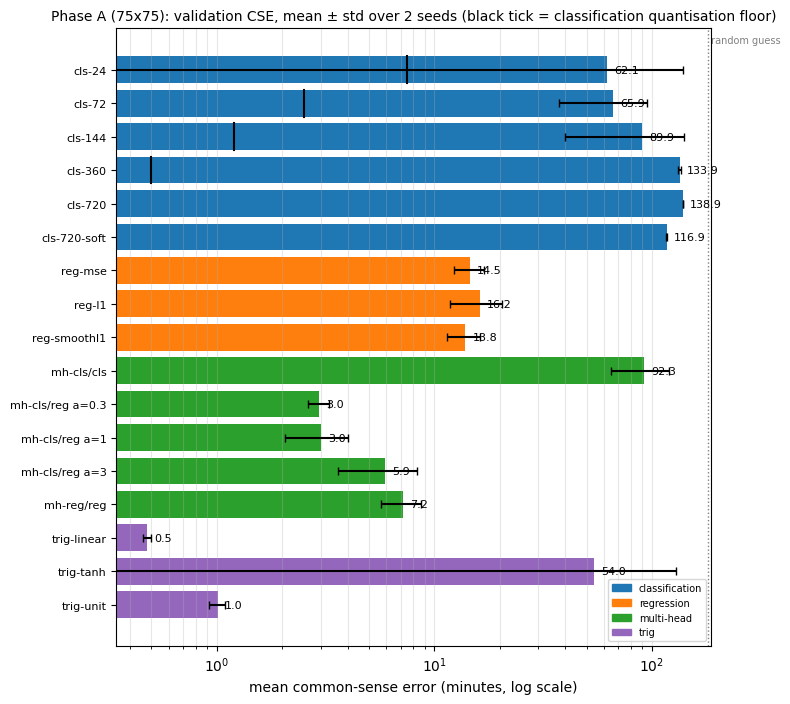

In [ ]:
def plot_bars(df, title, col="val_cse", err="val_cse_std"):
    df = df.reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(df) + 1.2))
    y = np.arange(len(df))
    ax.barh(y, df[col], xerr=df[err].fillna(0), color=[FAMILY_COLOR[f] for f in df["family"]], capsize=3)
    for yi, v in zip(y, df[col]):
        ax.text(v * 1.08, yi, f"{v:.1f}", va="center", fontsize=8)
    if "cls_floor" in df:
        for yi, fl in zip(y, df["cls_floor"]):
            if np.isfinite(fl):
                ax.plot([fl, fl], [yi - 0.4, yi + 0.4], color="k", lw=1.5)
    ax.set_yticks(y); ax.set_yticklabels(df["name"], fontsize=8); ax.invert_yaxis()
    ax.set_xscale("log"); ax.set_xlabel("mean common-sense error (minutes, log scale)")
    ax.axvline(180, color="grey", ls=":", lw=1); ax.text(180, -0.8, " random guess", fontsize=7, color="grey")
    handles = [plt.Rectangle((0, 0), 1, 1, color=FAMILY_COLOR[f]) for f in FAMILIES]
    ax.legend(handles, FAMILIES, fontsize=7, loc="lower right")
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", alpha=0.3, which="both")
    plt.tight_layout()
    return fig


plot_bars(dfA, f"Phase A (75x75): validation CSE, mean ± std over {len(SEEDS_A)} seeds "
               "(black tick = classification quantisation floor)").savefig(f"{OUT_DIR}/phaseA_bars.png", dpi=150)
plt.show()

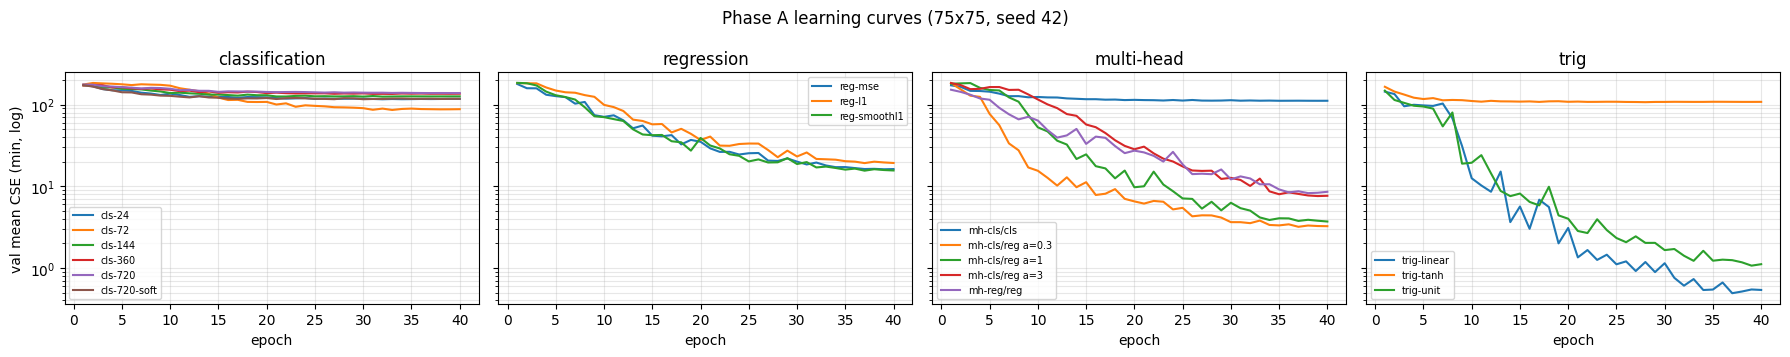

In [ ]:
# Validation CSE per epoch for every Phase A config (first seed), one panel per family
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, fam in zip(axes, FAMILIES):
    for c in CONFIGS_A:
        if c["family"] == fam:
            h_ = STORE[run_key(c, 75, SEEDS_A[0])]["hist"]["val_mean"]
            ax.plot(range(1, len(h_) + 1), h_, label=c["name"])
    ax.set_yscale("log"); ax.set_title(fam); ax.set_xlabel("epoch"); ax.legend(fontsize=7); ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("val mean CSE (min, log)")
plt.suptitle(f"Phase A learning curves (75x75, seed {SEEDS_A[0]})")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/phaseA_curves.png", dpi=150); plt.show()

### 6b. Selection and augmentation ablation
The best configuration of each family (lowest mean validation CSE) goes to Phase B. The overall best is also trained without augmentation, to measure what brightness/contrast/shift augmentation contributes.

In [ ]:
CFG_BY_NAME = {c["name"]: c for c in CONFIGS_A}
best_names = {fam: dfA[dfA["family"] == fam].sort_values("val_cse").iloc[0]["name"] for fam in FAMILIES}
print("Best per family (75x75, validation):")
for fam, nm in best_names.items():
    r = dfA[dfA["name"] == nm].iloc[0]
    print(f"  {fam:15s} {nm:20s} val CSE {r['val_cse']:.2f} ± {r['val_cse_std']:.2f} min")

if RUN_AUG_ABLATION:
    overall = dfA.sort_values("val_cse").iloc[0]["name"]
    noaug = {**CFG_BY_NAME[overall], "name": overall + " no-aug", "augment": False}
    run_configs([noaug], data75, SEEDS_A, "aug-ablation")
    dfAug = summarize([CFG_BY_NAME[overall], noaug], 75, SEEDS_A)
    dfAug.to_csv(f"{OUT_DIR}/aug_ablation_75px.csv", index=False)
    display(dfAug.round(2))

Best per family (75x75, validation):
  classification  cls-24               val CSE 62.11 ± 76.94 min
  regression      reg-smoothl1         val CSE 13.85 ± 2.40 min
  multi-head      mh-cls/reg a=0.3     val CSE 2.96 ± 0.33 min
  trig            trig-linear          val CSE 0.48 ± 0.02 min
aug-ablation: 1 configs x 2 seeds -> 0 runs to do


,name,family,res,val_cse,val_cse_std,val_median,best_epoch,time_min
0,trig-linear,trig,75,0.48,0.02,0.0,38.5,5.19
1,trig-linear no-aug,trig,75,0.25,0.04,0.0,40.0,5.02


## 7. Phase B: the best of each family on 150×150 (final results)
Each selected configuration is retrained on 150×150 with `SEEDS_B`. Its weights for the first seed are saved to `models/` for the analysis plots. This is the first time test CSE is shown.

In [ ]:
del data75
if torch.cuda.is_available():
    torch.cuda.empty_cache()
data150 = load_clocks(150)

150x150: /content/drive/MyDrive/IDL_A1/clocks/150/images.npy (uint8, 1s) | labels /content/drive/MyDrive/IDL_A1/clocks/150/labels.npy
  raw hour range 0..11, minute range 0..59
  train/val/test = [14400, 1800, 1800] | pixel mean 0.597 std 0.221


In [ ]:
CONFIGS_B = [CFG_BY_NAME[best_names[f]] for f in FAMILIES]
if data150 is not None:
    run_configs(CONFIGS_B, data150, SEEDS_B, "phaseB-150px", save=True)
    dfB = summarize(CONFIGS_B, 150, SEEDS_B, show_test=True)
    dfB.to_csv(f"{OUT_DIR}/phaseB_150px_final.csv", index=False)
    display(dfB.round(2))
else:
    print("150x150 data not found: Phase B skipped.")

phaseB-150px: 4 configs x 3 seeds -> 4 runs to do
  ep   1 | loss 3.1921 | val CSE mean 173.89 min, median 172.0
  ep   2 | loss 3.1790 | val CSE mean 167.52 min, median 157.0
  ep   3 | loss 3.1662 | val CSE mean 156.08 min, median 140.5
  ep   4 | loss 3.1505 | val CSE mean 149.30 min, median 130.0
  ep   5 | loss 3.1272 | val CSE mean 148.66 min, median 129.5
  ep   6 | loss 3.1045 | val CSE mean 145.73 min, median 123.0
  ep   7 | loss 3.0816 | val CSE mean 139.38 min, median 119.0
  ep   8 | loss 3.0585 | val CSE mean 134.36 min, median 116.0
  ep   9 | loss 3.0328 | val CSE mean 130.26 min, median 117.0
  ep  10 | loss 3.0094 | val CSE mean 135.00 min, median 116.0
  ep  11 | loss 2.9848 | val CSE mean 129.72 min, median 115.0
  ep  12 | loss 2.9654 | val CSE mean 123.65 min, median 107.0
  ep  13 | loss 2.9499 | val CSE mean 124.67 min, median 108.0
  ep  14 | loss 2.9319 | val CSE mean 125.26 min, median 110.0
  ep  15 | loss 2.9125 | val CSE mean 121.59 min, median 106.5
  ep 

,name,family,res,val_cse,val_cse_std,val_median,best_epoch,time_min,test_cse,test_cse_std,test_median,test_p90,within1_%,within5_%
0,cls-24,classification,150,117.08,0.54,101.33,28.00,1.10,118.38,0.90,102.00,271.33,2.02,6.44
1,reg-smoothl1,regression,150,26.50,4.16,17.33,39.00,31.86,27.26,3.99,17.67,59.03,4.93,16.61
2,mh-cls/reg a=0.3,multi-head,150,5.78,2.31,2.83,39.00,31.98,6.55,3.00,3.00,15.40,28.69,74.89
3,trig-linear,trig,150,38.62,60.56,34.17,33.67,21.25,39.08,62.08,35.33,79.67,55.26,66.04


## 8. Analysis plots (final 150×150 models)

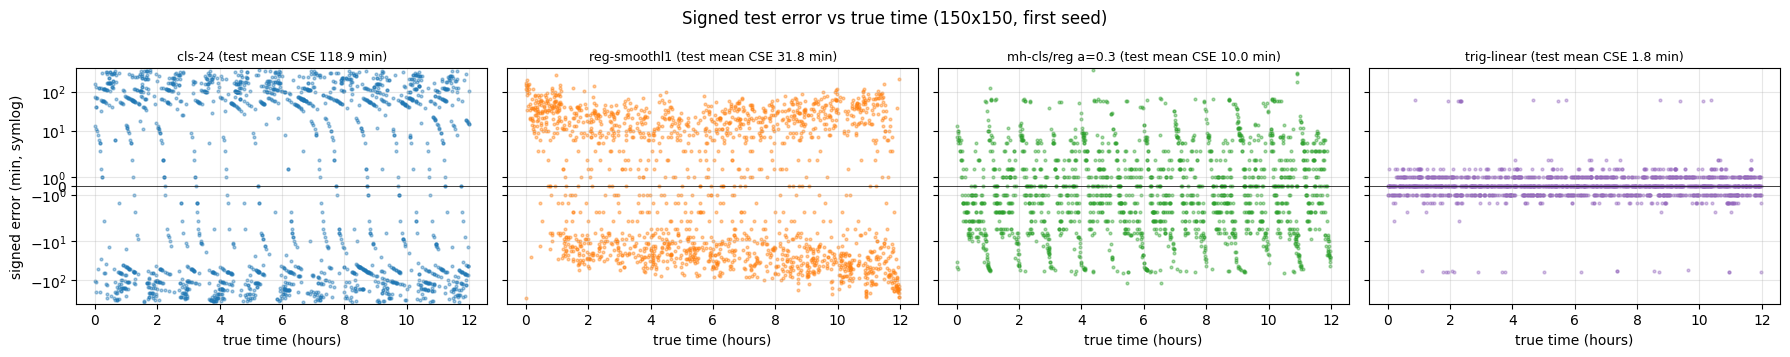

In [ ]:
FINAL_RES = 150 if data150 is not None else 75
FINAL_DATA = data150


def final_rec(cfg, seed=None):
    seeds = SEEDS_B if FINAL_RES == 150 else SEEDS_A
    return STORE[run_key(cfg, FINAL_RES, seeds[0] if seed is None else seed)]


# 8a. Signed error vs true time: shows the wrap-around problem of regression near 12:00
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, c in zip(axes, CONFIGS_B):
    r = final_rec(c)
    tt, pp = np.array(r["test_true"]), np.array(r["test_pred"])
    se = signed_error(pp, tt)
    ax.scatter(tt / 60, se, s=4, alpha=0.4, color=FAMILY_COLOR[c["family"]])
    ax.set_yscale("symlog", linthresh=5)
    ax.set_ylim(-400, 400)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(f"{c['name']} (test mean CSE {np.abs(se).mean():.1f} min)", fontsize=9)
    ax.set_xlabel("true time (hours)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("signed error (min, symlog)")
plt.suptitle(f"Signed test error vs true time ({FINAL_RES}x{FINAL_RES}, first seed)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/final_error_vs_time.png", dpi=150); plt.show()

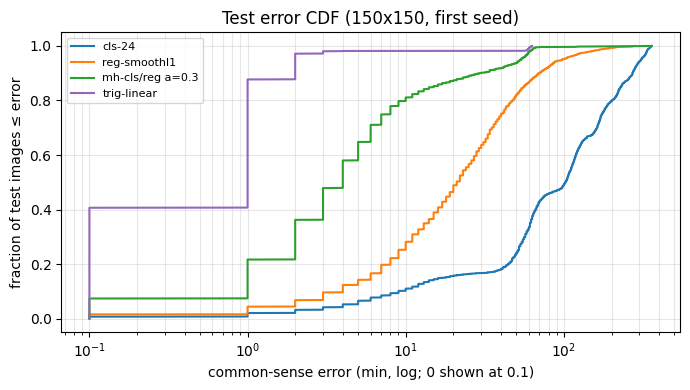

In [ ]:
# 8b. Cumulative distribution of test errors
fig, ax = plt.subplots(figsize=(7, 4))
for c in CONFIGS_B:
    r = final_rec(c)
    e = np.sort(cse(np.array(r["test_pred"], float), np.array(r["test_true"], float)))
    ax.plot(np.maximum(e, 0.1), np.arange(1, len(e) + 1) / len(e), label=c["name"], color=FAMILY_COLOR[c["family"]])
ax.set_xscale("log"); ax.set_xlabel("common-sense error (min, log; 0 shown at 0.1)")
ax.set_ylabel("fraction of test images ≤ error"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title(f"Test error CDF ({FINAL_RES}x{FINAL_RES}, first seed)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/final_error_cdf.png", dpi=150); plt.show()

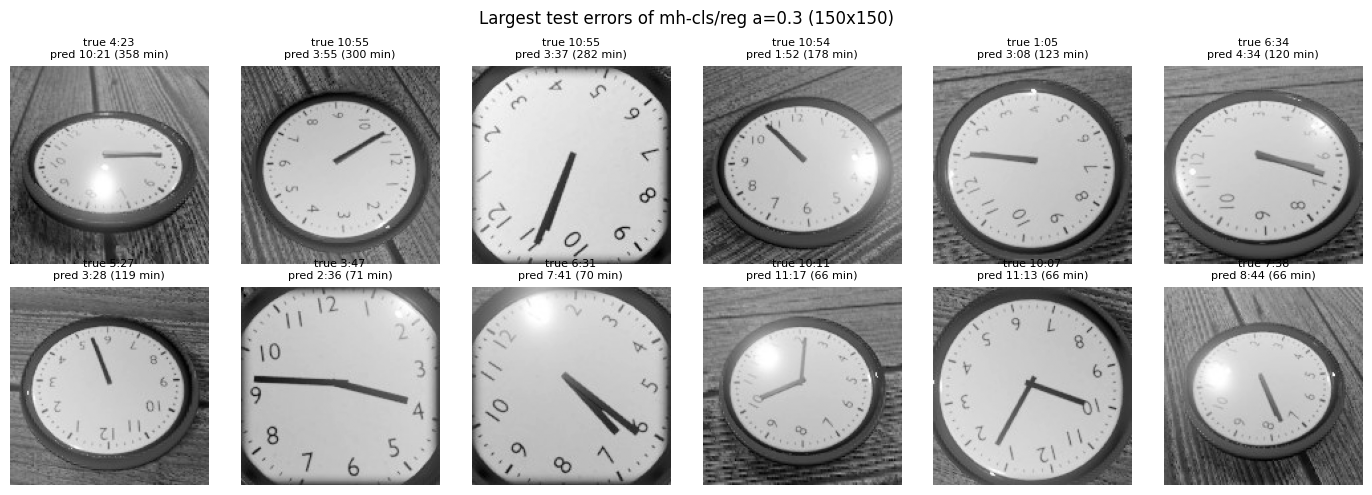

mh-cls/reg a=0.3: test mean CSE 9.97 min, median 4.0, 21.7% within 1 min, 64.8% within 5 min


In [ ]:
# 8c. Worst test predictions of the best final model
if FINAL_DATA is not None:
    best_final = dfB.sort_values("val_cse").iloc[0]["name"]
    cfg = next(c for c in CONFIGS_B if c["name"] == best_final)
    r = final_rec(cfg)
    # test predictions are stored with the run (same order as FINAL_DATA["test"]), so no model reload is needed
    pt, tt = np.array(r["test_pred"], dtype=float), np.array(r["test_true"], dtype=float)
    assert np.array_equal(tt, minutes_of(*FINAL_DATA["test"][1:]).cpu().numpy()), "test order mismatch"
    err = cse(pt, tt)
    worst = np.argsort(-err)[:12]
    fmt = lambda t: f"{int(t) // 60}:{int(t) % 60:02d}"
    fig, axes = plt.subplots(2, 6, figsize=(14, 5))
    for ax, i in zip(axes.flat, worst):
        ax.imshow(FINAL_DATA["test"][0][i, 0].cpu(), cmap="gray")
        ax.set_title(f"true {fmt(tt[i])}\npred {fmt(pt[i])} ({err[i]:.0f} min)", fontsize=8)
        ax.axis("off")
    plt.suptitle(f"Largest test errors of {best_final} ({FINAL_RES}x{FINAL_RES})")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/final_worst_cases.png", dpi=150); plt.show()
    print(f"{best_final}: test mean CSE {err.mean():.2f} min, median {np.median(err):.1f}, "
          f"{100 * (err <= 1).mean():.1f}% within 1 min, {100 * (err <= 5).mean():.1f}% within 5 min")